INFO       Cache size for target 'cython': 1127 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]
INFO:root:creating /tmp/brian_flag_test_03zr1v4p/tmp
INFO:root:creating /tmp/brian_flag_test_03zr1v4p/tmp/brian_flag_test_03zr1v4p
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_03zr1v4p/flag_test.cpp -o /tmp/brian_flag_test_03zr1v4p/tmp/brian_flag_test_03zr1v4p/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_a_9nssue/tmp
INFO:root:creating /tmp/brian_flag_test_a_9nssue/tmp/brian_flag_test_a_9nssue
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_a_9nssue/flag_test.cpp -o /tmp/brian_flag_test_a_9nssue/tmp/brian_flag_test_a_9nssue/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_8v1t4khe/tmp
INFO:root:creating /tmp/brian_f

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 10
Output neuron 0 is connected to input neurons: 20
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 11
Output neuron 0 is connected to input neurons: 21
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 22
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 11
Output neuron 1 is connected to input neurons: 21
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 12
Output neuron 1 is connected to input neurons: 22
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 23
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 12
Output 

INFO:root:building '_cython_magic_64613c1cbdfd65a49d37741dc37d5be1' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_64613c1cbdfd65a49d37741dc37d5be1.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_64613c1cbdfd65a49d37741dc37d5be1.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_64613c1cbdfd65a49d37741dc37d5be1.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 10. s
6.494 s (64%) simulated in 10s, estimated 6s remaining.
10. s (100%) simulated in 16s


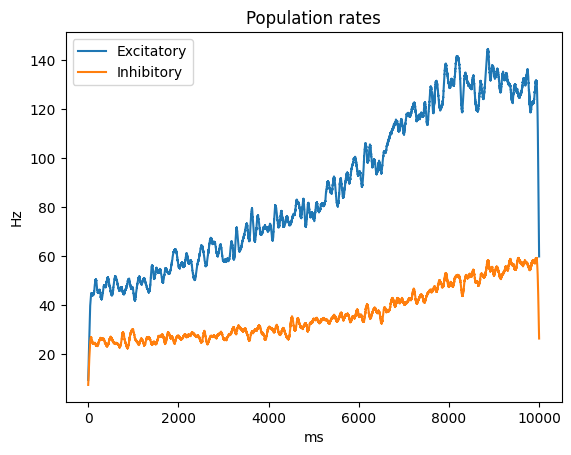

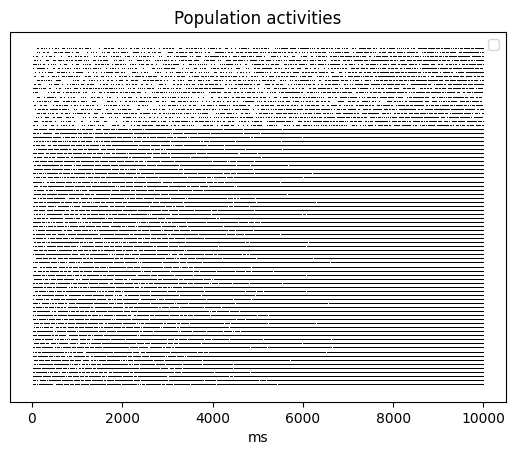

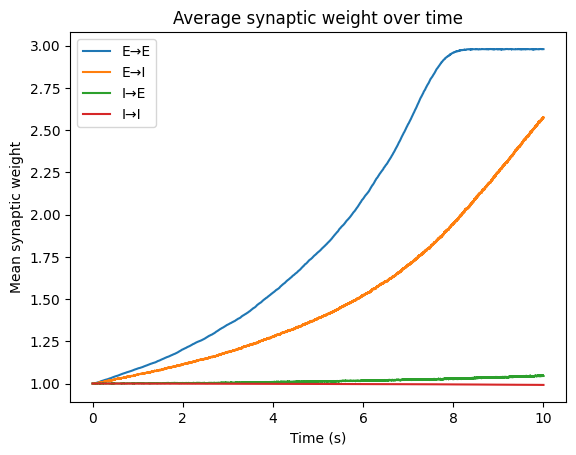

WARNING    /tmp/ipykernel_1397/3187651275.py:368: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_1397/3187651275.py:369: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)



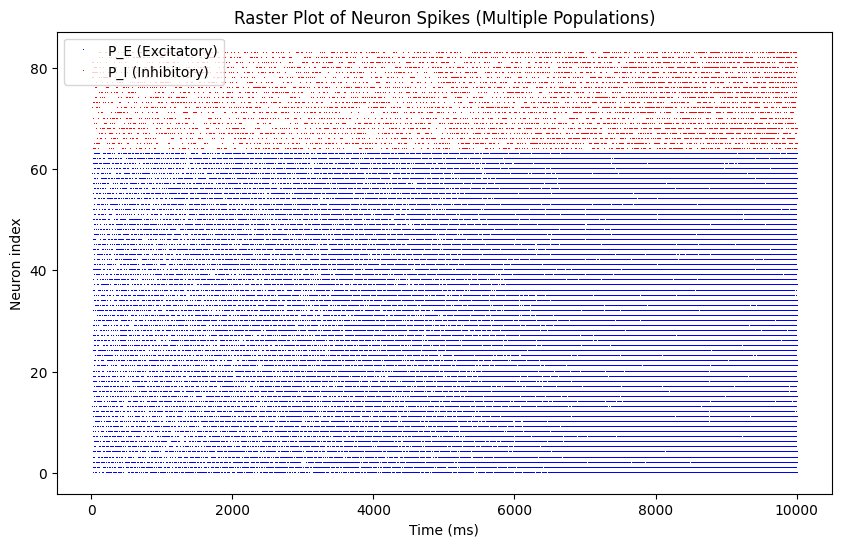

In [ ]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import spectrogram
from scipy.signal import cwt, morlet2


start_scope()

#gif 
save_interval = 0.1*second  
frames = []
def plot_weights_for_gif(t):
    # Build a full weight matrix from Synapses (N_E x N_E)
    W = np.zeros((N_E, N_E))
    for i, j, w_ij in zip(C_E_E.i[:], C_E_E.j[:], C_E_E.w[:]):
        W[i, j] = w_ij
    
    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()

# Phase durations
simu_duration = 10 * second



# populations
n_input_rows = 10  
n_input_columns = 10  
n_output_rows = 8  
n_output_columns = 8  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
N_I = int(N_inp * 0.2)  
target_rate = 5*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''


Apre = 0.012
Apost = -0.01 
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#pattern
pg_inp = PoissonGroup(N_inp, 50 * Hz, name = 'inp')
C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
        s_AMPA_ext += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
    ''',
    on_post='''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
    ''',
    method='euler')
C_PG_E.connect(False)  

rf_size = 3  
half_rf = rf_size // 2


for out_y in range(n_output_rows):
    for out_x in range(n_output_columns):
        out_index = out_y * n_output_columns + out_x  
        for dx in range(3):  # -1,2
            for dy in range(3):
                in_x = out_x + dx
                in_y = out_y + dy
                if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                    in_index = in_y * n_input_columns + in_x  
                    C_PG_E.connect(i=in_index, j=out_index)       
                    print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

C_PG_E.w[:] = 1
C_PG_E.taupre = 20*ms
C_PG_E.taupost = 20*ms

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


# @network_operation(dt=save_interval)
# def capture_frames():
#     plot_weights_for_gif(defaultclock.t)


# @network_operation(dt=plasticity_dt)
# def homeostatic_plasticity():
#     t_now = defaultclock.t
#     if t_now < window:
#         return
#     t0 = t_now - window
#     #E
#     times = sp_E.t
#     idxs  = sp_E.i
#     rates = np.zeros(N_E)*Hz
#     for post in range(N_E):
#         mask = np.logical_and(idxs == post, times >= t0)
#         count = np.sum(mask)
#         rates[post] = count/window
#         delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
#         for pre in range(N_E):
#             if pre == post:
#                 continue
#             C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
#     print(f"[{t_now/ms:.0f} ms]  "
#           f"rates (mean): {np.mean(rates):.1f} Hz  ")  
#     #I
#     times1 = sp_E.t
#     idxs1  = sp_E.i
#     rates1 = np.zeros(N_E)*Hz
#     rates2 = np.zeros(N_E)*Hz
#     for post in range(N_E):  
#         mask1 = np.logical_and(idxs1 == post, times1 >= t0)
#         count1 = np.sum(mask1)
#         rates1[post] = count1 / window
#     avg_rate_E = np.mean(rates1) 
#     C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)



net = Network(collect())
net.run(simu_duration, report='stdout') # 

# def create_gif():
#     # Convert saved frames to GIF
#     gif_filename = 'weight_connections.gif'
#     with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
#         for frame in frames:
#             # Convert the figure to an image
#             image_path = 'temp_frame.png'
#             frame.savefig(image_path)
#             image = imageio.imread(image_path)
#             writer.append_data(image)
#             os.remove(image_path)  # Remove the temporary image after adding it to the GIF
    
#     print(f"GIF saved as {gif_filename}")
# create_gif()


# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()



In [12]:
conn_data = C_PG_E.get_states(['i', 'j'])
print(conn_data)

{'i': array([ 0, 10, 20,  1, 11, 21,  2, 12, 22,  1, 11, 21,  2, 12, 22,  3, 13,
       23,  2, 12, 22,  3, 13, 23,  4, 14, 24,  3, 13, 23,  4, 14, 24,  5,
       15, 25,  4, 14, 24,  5, 15, 25,  6, 16, 26,  5, 15, 25,  6, 16, 26,
        7, 17, 27,  6, 16, 26,  7, 17, 27,  8, 18, 28,  7, 17, 27,  8, 18,
       28,  9, 19, 29, 10, 20, 30, 11, 21, 31, 12, 22, 32, 11, 21, 31, 12,
       22, 32, 13, 23, 33, 12, 22, 32, 13, 23, 33, 14, 24, 34, 13, 23, 33,
       14, 24, 34, 15, 25, 35, 14, 24, 34, 15, 25, 35, 16, 26, 36, 15, 25,
       35, 16, 26, 36, 17, 27, 37, 16, 26, 36, 17, 27, 37, 18, 28, 38, 17,
       27, 37, 18, 28, 38, 19, 29, 39, 20, 30, 40, 21, 31, 41, 22, 32, 42,
       21, 31, 41, 22, 32, 42, 23, 33, 43, 22, 32, 42, 23, 33, 43, 24, 34,
       44, 23, 33, 43, 24, 34, 44, 25, 35, 45, 24, 34, 44, 25, 35, 45, 26,
       36, 46, 25, 35, 45, 26, 36, 46, 27, 37, 47, 26, 36, 46, 27, 37, 47,
       28, 38, 48, 27, 37, 47, 28, 38, 48, 29, 39, 49, 30, 40, 50, 31, 41,
       51, 32, 42, 

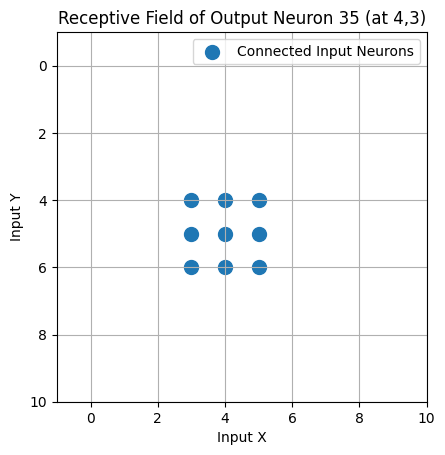

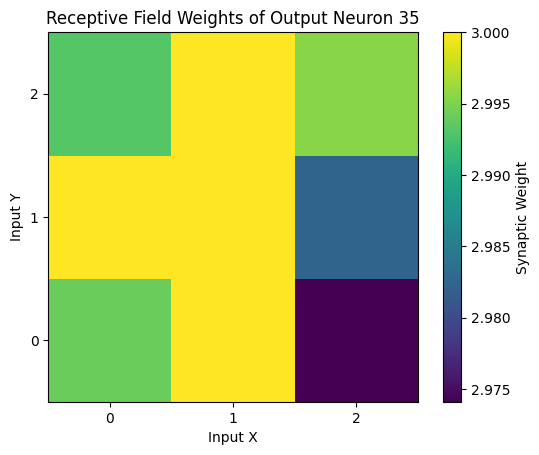

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# --- CONFIG ---
out_idx = 35  
receptive_field_size = 3

def idx_to_xy(idx, ncols):
    return (idx // ncols, idx % ncols)

conn_data = C_PG_E.get_states(['i', 'j', 'w'])

input_indices = conn_data['i'][conn_data['j'] == out_idx]
weights = conn_data['w'][conn_data['j'] == out_idx]

input_coords = np.array([idx_to_xy(i, n_input_columns) for i in input_indices])  
x_out, y_out = idx_to_xy(out_idx, n_output_columns)  

fig, ax = plt.subplots()
ax.scatter(*input_coords.T[::-1], s=100, label='Connected Input Neurons')  
ax.set_title(f'Receptive Field of Output Neuron {out_idx} (at {x_out},{y_out})')
ax.set_xlim(-1, n_input_columns)
ax.set_ylim(-1, n_input_rows)
ax.invert_yaxis()
ax.set_aspect('equal')
ax.grid(True)
ax.legend()
plt.xlabel("Input X")
plt.ylabel("Input Y")
plt.show()

rf_matrix = np.zeros((receptive_field_size, receptive_field_size))

rf_indices = input_coords - np.min(input_coords, axis=0)
for coord, w in zip(rf_indices, weights):
    y, x = coord  
    if 0 <= x < receptive_field_size and 0 <= y < receptive_field_size:
        rf_matrix[y, x] = w

plt.imshow(rf_matrix, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Synaptic Weight')
plt.title(f'Receptive Field Weights of Output Neuron {out_idx}')
plt.xticks(range(receptive_field_size))
plt.yticks(range(receptive_field_size))
plt.gca().invert_yaxis()
plt.xlabel("Input X")
plt.ylabel("Input Y")
plt.show()


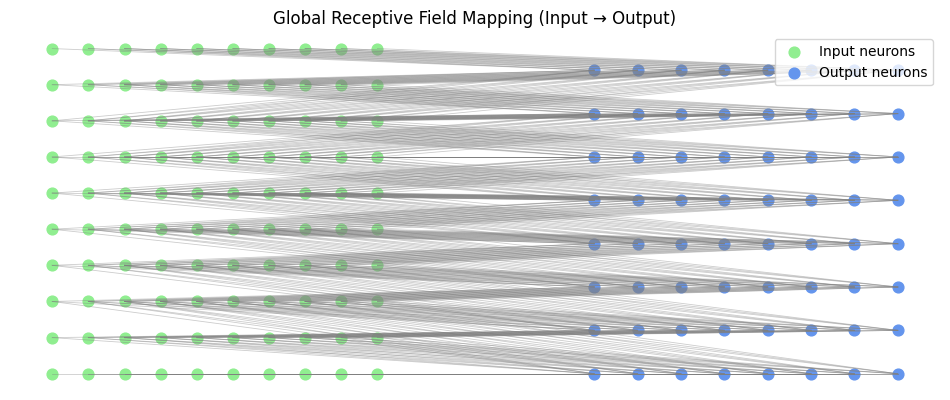

In [11]:

n_input_rows = 10
n_input_cols = 10
n_output_rows = 8
n_output_cols = 8
receptive_field_size = 3
def neuron_grid_coords(rows, cols, spacing=1.0, offset=(0, 0)):
    X, Y = np.meshgrid(np.arange(cols), np.arange(rows))
    coords = np.stack([X.flatten(), Y.flatten()], axis=1)
    return coords * spacing + np.array(offset)

conn_data = C_PG_E.get_states(['i', 'j'])

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_title("Global Receptive Field Mapping (Input → Output)")

# Input and output positions
input_coords = neuron_grid_coords(n_input_rows, n_input_cols)
output_coords = neuron_grid_coords(n_output_rows, n_output_cols, offset=(15, 0), spacing=1.2)

# Draw neurons
ax.scatter(input_coords[:, 0], input_coords[:, 1], c='lightgreen', s=60, label='Input neurons')
ax.scatter(output_coords[:, 0], output_coords[:, 1], c='cornflowerblue', s=60, label='Output neurons')

# Draw connections
for out_idx in range(n_output_rows * n_output_cols):
    out_x, out_y = output_coords[out_idx]
    inp_idxs = conn_data['i'][conn_data['j'] == out_idx]
    for inp_idx in inp_idxs:
        in_x, in_y = input_coords[inp_idx]
        ax.plot([in_x, out_x], [in_y, out_y], c='gray', alpha=0.4, linewidth=0.6)

ax.legend()
ax.set_aspect('equal')
ax.axis('off')
plt.show()


INFO:root:building '_cython_magic_7f839ba00c2862ab2d6dbc7f992dff21' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_7f839ba00c2862ab2d6dbc7f992dff21.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_7f839ba00c2862ab2d6dbc7f992dff21.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_7f839ba00c2862ab2d6dbc7f992dff21.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 10
Output neuron 0 is connected to input neurons: 20
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 11
Output neuron 0 is connected to input neurons: 21
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 22
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 11
Output neuron 1 is connected to input neurons: 21
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 12
Output neuron 1 is connected to input neurons: 22
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 23
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 12
Output 

INFO:root:building '_cython_magic_460741baa561a1a815e8b79f9a9d7f8e' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_460741baa561a1a815e8b79f9a9d7f8e.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_460741baa561a1a815e8b79f9a9d7f8e.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_460741baa561a1a815e8b79f9a9d7f8e.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 10. s
6.5537 s (65%) simulated in 11s, estimated 6s remaining.
10. s (100%) simulated in 16s


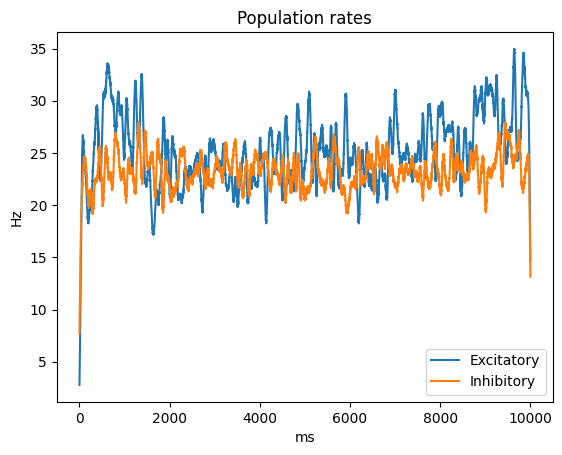

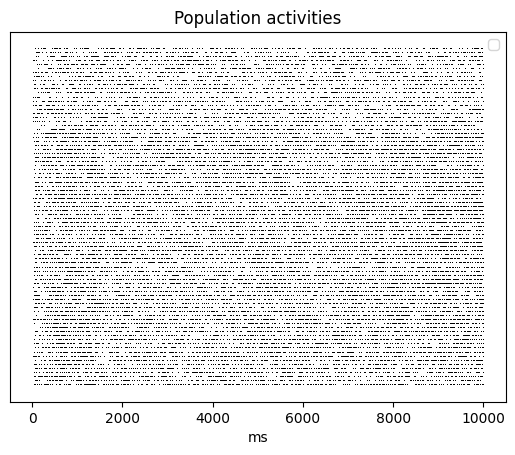

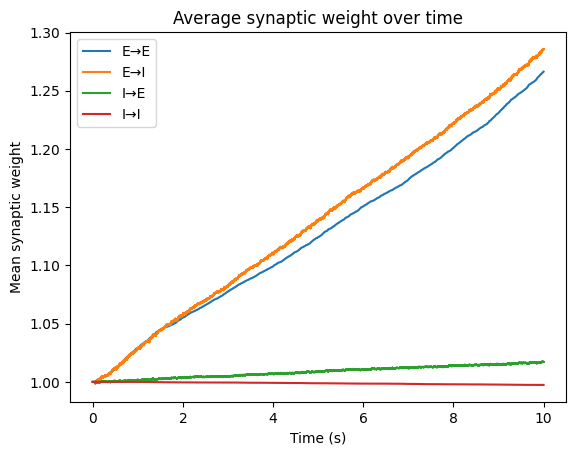

WARNING    /tmp/ipykernel_1326/2554501897.py:417: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_1326/2554501897.py:418: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)



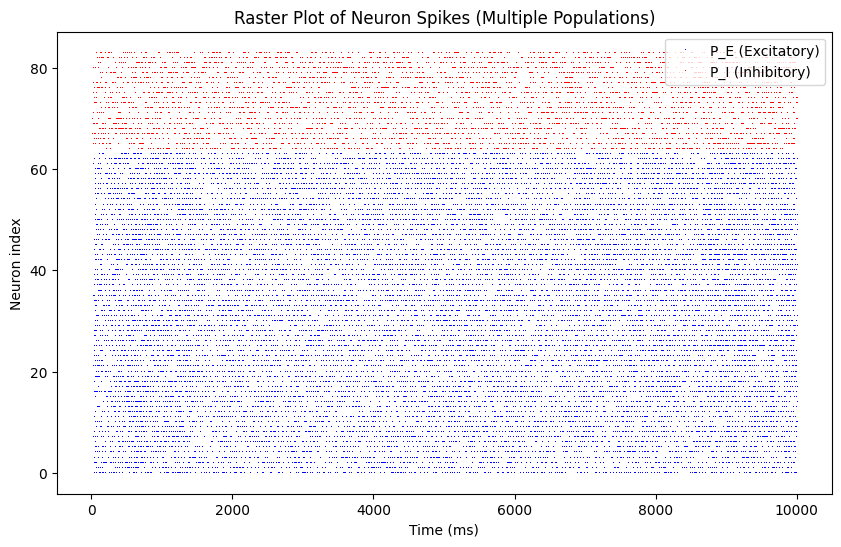

In [14]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
# from scipy.signal import spectrogram
# from scipy.signal import cwt, morlet2
from scipy.signal import convolve2d

def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered
#prepare inputs
kernel = np.array([
    [0,  -1,  0],
    [-1,  4, -1],
    [0,  -1,  0]
], dtype=np.float32)

def generate_bar_image(shape=(12, 12), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=50*Hz):
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates

pattern_duration = 350*ms
num_patterns = 5

images = [generate_bar_image((12, 12), 3) for _ in range(num_patterns)]
rate_seq = [convert_to_rates(mexican_hat(img)) for img in images]

rate_array = np.repeat(rate_seq, int(pattern_duration/defaultclock.dt), axis=0)
input_rate_timed = TimedArray(rate_array, dt=defaultclock.dt)


start_scope()

#gif 
save_interval = 0.1*second  
frames = []
def plot_weights_for_gif(t):
    # Build a full weight matrix from Synapses (N_E x N_E)
    W = np.zeros((N_E, N_E))
    for i, j, w_ij in zip(C_E_E.i[:], C_E_E.j[:], C_E_E.w[:]):
        W[i, j] = w_ij
    
    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()

# Phase durations
simu_duration = 10 * second



# populations
n_input_rows = 10  
n_input_columns = 10  
n_output_rows = 8  
n_output_columns = 8  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
N_I = int(N_inp * 0.2)  
target_rate = 5*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''


Apre = 0.012
Apost = -0.01 
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#pattern
pg_inp = PoissonGroup(N_inp, rates='input_rate_timed(t, i) * Hz', name = 'inp')
C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
        s_AMPA_ext += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
    ''',
    on_post='''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
    ''',
    method='euler')
C_PG_E.connect(False)  

rf_size = 3  
half_rf = rf_size // 2


for out_y in range(n_output_rows):
    for out_x in range(n_output_columns):
        out_index = out_y * n_output_columns + out_x  
        for dx in range(3):  # -1,2
            for dy in range(3):
                in_x = out_x + dx
                in_y = out_y + dy
                if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                    in_index = in_y * n_input_columns + in_x  
                    C_PG_E.connect(i=in_index, j=out_index)       
                    print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

C_PG_E.w[:] = 1
C_PG_E.taupre = 20*ms
C_PG_E.taupost = 20*ms

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


# @network_operation(dt=save_interval)
# def capture_frames():
#     plot_weights_for_gif(defaultclock.t)


# @network_operation(dt=plasticity_dt)
# def homeostatic_plasticity():
#     t_now = defaultclock.t
#     if t_now < window:
#         return
#     t0 = t_now - window
#     #E
#     times = sp_E.t
#     idxs  = sp_E.i
#     rates = np.zeros(N_E)*Hz
#     for post in range(N_E):
#         mask = np.logical_and(idxs == post, times >= t0)
#         count = np.sum(mask)
#         rates[post] = count/window
#         delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
#         for pre in range(N_E):
#             if pre == post:
#                 continue
#             C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
#     print(f"[{t_now/ms:.0f} ms]  "
#           f"rates (mean): {np.mean(rates):.1f} Hz  ")  
#     #I
#     times1 = sp_E.t
#     idxs1  = sp_E.i
#     rates1 = np.zeros(N_E)*Hz
#     rates2 = np.zeros(N_E)*Hz
#     for post in range(N_E):  
#         mask1 = np.logical_and(idxs1 == post, times1 >= t0)
#         count1 = np.sum(mask1)
#         rates1[post] = count1 / window
#     avg_rate_E = np.mean(rates1) 
#     C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)



net = Network(collect())
net.run(simu_duration, report='stdout') # 

# def create_gif():
#     # Convert saved frames to GIF
#     gif_filename = 'weight_connections.gif'
#     with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
#         for frame in frames:
#             # Convert the figure to an image
#             image_path = 'temp_frame.png'
#             frame.savefig(image_path)
#             image = imageio.imread(image_path)
#             writer.append_data(image)
#             os.remove(image_path)  # Remove the temporary image after adding it to the GIF
    
#     print(f"GIF saved as {gif_filename}")
# create_gif()


# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()



In [1]:
import numpy as np
import matplotlib.pyplot as plt
kernel = np.array([
    [0,  -1,  0],
    [-1,  4, -1],
    [0,  -1,  0]
], dtype=np.float32)

In [2]:
def generate_bar_image(shape=(12, 12), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img

In [3]:
from scipy.signal import convolve2d

def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

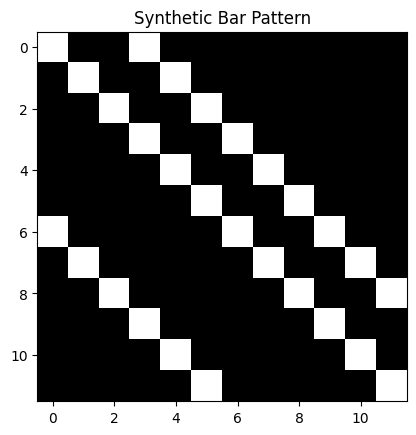

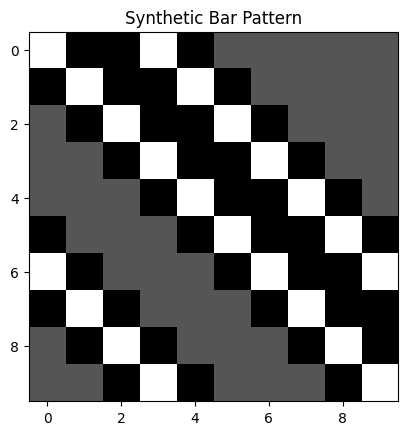

In [11]:
img = generate_bar_image((12, 12), n_bars=3)
plt.imshow(img, cmap='gray')
plt.title("Synthetic Bar Pattern")
plt.show()
filtered=apply_mexican_hat(img)
plt.imshow(filtered, cmap='gray')
plt.title("Synthetic Bar Pattern")
plt.show()

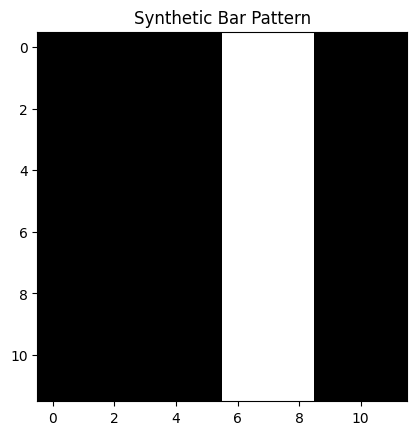

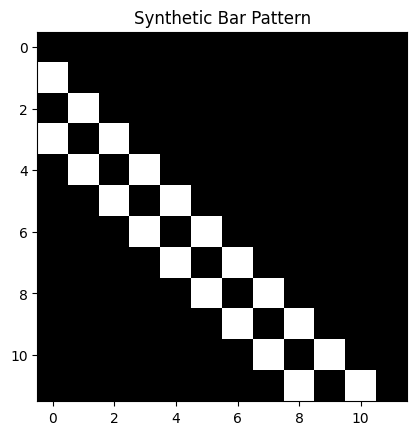

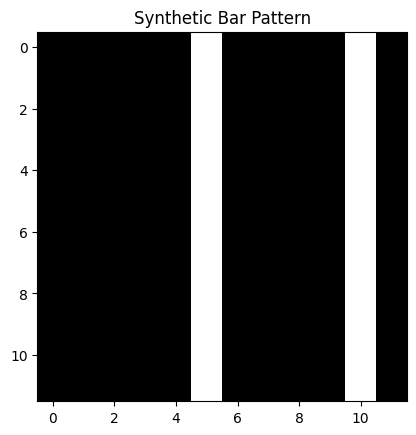

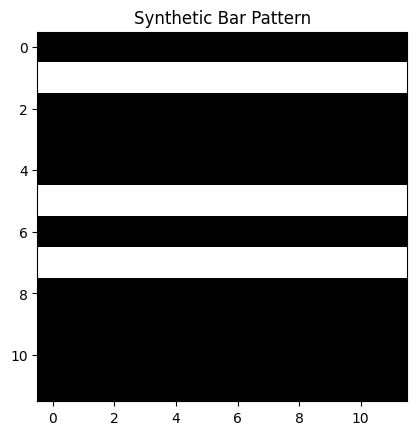

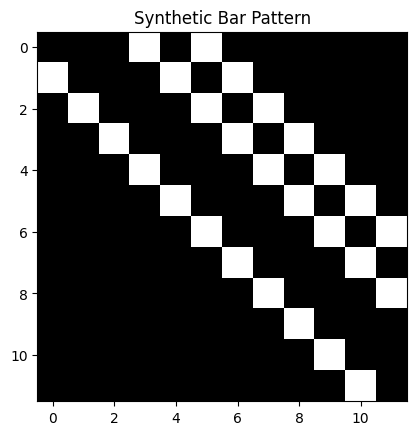

[25. 25. 25. 25.  0. 50. 25. 50.  0. 25. 25. 25. 25. 25.  0. 50. 25. 50.
  0. 25. 25. 25. 25. 25.  0. 50. 25. 50.  0. 25. 25. 25. 25. 25.  0. 50.
 25. 50.  0. 25. 25. 25. 25. 25.  0. 50. 25. 50.  0. 25. 25. 25. 25. 25.
  0. 50. 25. 50.  0. 25. 25. 25. 25. 25.  0. 50. 25. 50.  0. 25. 25. 25.
 25. 25.  0. 50. 25. 50.  0. 25. 25. 25. 25. 25.  0. 50. 25. 50.  0. 25.
 25. 25. 25. 25.  0. 50. 25. 50.  0. 25.] Hz^2
[12.5 25.  25.  25.  25.  25.  25.  25.  25.  25.  50.  12.5 25.  25.
 25.  25.  25.  25.  25.  25.   0.  50.  12.5 25.  25.  25.  25.  25.
 25.  25.  50.   0.  50.  12.5 25.  25.  25.  25.  25.  25.  12.5 50.
  0.  50.  12.5 25.  25.  25.  25.  25.  25.  12.5 50.   0.  50.  12.5
 25.  25.  25.  25.  25.  25.  12.5 50.   0.  50.  12.5 25.  25.  25.
 25.  25.  25.  12.5 50.   0.  50.  12.5 25.  25.  25.  25.  25.  25.
 12.5 50.   0.  50.  12.5 25.  25.  25.  25.  25.  25.  12.5 50.   0.
 50.  12.5] Hz^2
[16.666668 16.666668 16.666668  0.       50.        0.       16.666668
 16.66666

In [20]:
def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered
#prepare inputs
kernel = np.array([
    [0,  -1,  0],
    [-1,  4, -1],
    [0,  -1,  0]
], dtype=np.float32)

def generate_bar_image(shape=(12, 12), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=50*Hz):
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates

pattern_duration = 350*ms
num_patterns = 5

images = [generate_bar_image((12, 12), 3) for _ in range(num_patterns)]
rate_seq = [convert_to_rates(mexican_hat(img)) for img in images]

rate_array = np.repeat(rate_seq, int(pattern_duration/defaultclock.dt), axis=0)
input_rate_timed = TimedArray(rate_array, dt=defaultclock.dt)

for img in images:
    plt.imshow(img, cmap='gray')
    plt.title("Synthetic Bar Pattern")
    plt.show()
for rate in rate_seq:
    print(rate)
# plt.imshow(filtered, cmap='gray')
# plt.title("Synthetic Bar Pattern")
# plt.show()